# Les effets du vent sur les traumatismes et le crime en France

Un projet de Matthieu Bonnet et Jade Valade, ENSAE 2026

*Pour lancer ce notebook, veuillez au préalable lancer la commande `pip install -r "requirements.txt"`.* \
*À noter également que certaines fonctions sont issues du fichier fonctions_projet.py.* \
*Certaines cellules ont un temps d'exécution un peu long pour la récupération de données par API, comptez 5 à 10 minutes pour l'éxécution complète du Notebook.*

*Bonne lecture !*

In [2]:
from fonctions_projet import*

## Récupération des données

### **Données météo**

### Récupération des données de vent depuis data.gouv.fr

Le code récupère automatiquement les données de vent de tous les départements :

1. **Liste des fichiers** : une requête à l'API de data.gouv.fr (`/api/1/datasets/...`) renvoie la fiche du jeu « Données climatologiques de base - quotidiennes ».
2. **Sélection des fichiers d'intérêt** : On ne garde que les fichiers départementaux couvrant la période 1950-2024 et contenant les variables de vent. On obtient une liste de dictionnaires, avec un fichier par département (DROM et COM inclus).
3. **Lecture de chaque fichier** : chaque fichier compressé (`csv.gz`) est lu directement depuis son lien, en ne gardant que quatre colonnes : `NUM_POSTE`, `AAAAMMJJ` (date), `FFM` (vent moyen) et `FXI3S` (rafale maximale).
4. **Filtre temporel** : seules les lignes à partir du 1er janvier 2016 sont conservées.
5. **Fusion** : les tableaux de tous les départements sont concaténés en un seul DataFrame, `meteoDF`.

**Temps d'exécution** : Les fichiers sont lus depuis le réseau à chaque exécution, ce qui est lent. (environ 5 minutes)

In [ ]:
import requests
import pandas as pd
import re

r = requests.get(
    "https://www.data.gouv.fr/api/1/datasets/donnees-climatologiques-de-base-quotidiennes/",
    headers={"X-Fields": "id,title,resources{title,format,type,latest}"},
)

fiche = r.json()

pattern = r'QUOT_departement_\d+_periode_1950-2024_RR-T-Vent'

fichiers_interet = [fiche['resources'][i] for i in range(len(fiche['resources'])) if re.fullmatch(pattern, fiche['resources'][i]['title']) ] ## On filtre sur les jeux de données qui nous intéressent

variables_vent_1 = ['NUM_POSTE', 'AAAAMMJJ', 'FFM', 'FXI3S']
donnees_vent = []
nbre_departement = 0
for i in range(len(fichiers_interet)):
    print(f"nombre de départements importés : {nbre_departement}", end="\r")
    donnees_interet = pd.read_csv(fichiers_interet[i]['latest'],sep=';',dtype = {'NUM_POSTE' : str}, usecols = variables_vent_1, compression="gzip")
    donnes_interet_filtre = donnees_interet[donnees_interet["AAAAMMJJ"] >= 20160101]
    donnees_vent.append(donnes_interet_filtre)
    nbre_departement += 1
print(f"nombre de départements importés : {len(fichiers_interet)}")

meteoDF = pd.concat(donnees_vent, ignore_index=True)

nombre de départements importés : 106


In [31]:
meteoDF.head()

,DATE,annee_iso,semaine_iso,dep,cle_semaine,vent_moyen_ms,rafale_max_ms
0,2016-01-01,2015,53,01,"(01, 53, 2015)",2.0,14.2
1,2016-01-02,2015,53,01,"(01, 53, 2015)",1.1,10.2
2,2016-01-03,2015,53,01,"(01, 53, 2015)",2.6,17.4
3,2016-01-04,2016,1,01,"(01, 1, 2016)",2.9,12.3
4,2016-01-05,2016,1,01,"(01, 1, 2016)",1.8,7.4


## Préparation du tableau de données

À partir du tableau d'origine (une ligne par station et par jour), on a effectué plusieurs transformations :

1. **Création de la variable `dep`** : elle est déduite des deux (ou trois) premiers chiffres du numéro de station (`NUM_POSTE`), qui correspondent au code du département.
2. **Agrégation par département** : pour chaque département (et chaque année), on a calculé la **moyenne** des valeurs de l'ensemble des stations du département, afin d'obtenir une seule mesure par département. Les valeurs manquantes (`NaN`) sont ignorées par le calcul de la moyenne, qui porte donc sur les valeurs disponibles. Cela évite de les traiter comme des zéros. Cependant une moyenne calculée sur peu de mesures est moins fiable.
3. **Renommage des variables** pour les rendre plus lisibles :
   - `FFM` devient `vent_moyen_ms` : moyenne quotidienne du vent moyenné sur 10 minutes, à 10 m (en m/s) ;
   - `FXI3S` devient `rafale_max_ms` : maximum quotidien du vent moyenné sur 3 secondes, à 10 m (en m/s).
4. **Création de variables temporelles** : extraction de la semaine ISO 8601 (`semaine_iso`) et de l'année ISO 8601 (`annee_iso`) à partir de la date.
5. **Création d'une clé de jointure** (`cle_semaine`) associant le département, la semaine ISO et l'année ISO.

In [5]:

meteoDF = meteoDF.rename(columns = {'AAAAMMJJ' : 'DATE'})
meteoDF['DATE'] = pd.to_datetime(meteoDF['DATE'], format = '%Y%m%d' )
meteoDF = meteoDF.rename(columns={"FFM": "vent_moyen_ms","FXI3S": "rafale_max_ms"})

meteoDF['dep'] = meteoDF['NUM_POSTE'].str[:2]
#meteoDF.loc[meteoDF['dep'].astype(int) > 95, "dep"] = meteoDF.loc[df_final1['dep'].astype(int) > 95, "NUM_POSTE"].str[:3]
meteoDF["semaine_iso"] = meteoDF["DATE"].dt.isocalendar().week
meteoDF["annee_iso"] = meteoDF["DATE"].dt.isocalendar().year
meteoDF["cle_semaine"] = list(zip(meteoDF["dep"], meteoDF["semaine_iso"], meteoDF["annee_iso"]))
meteoDF = meteoDF[["DATE", "annee_iso", "semaine_iso", "dep", "cle_semaine", "vent_moyen_ms", "rafale_max_ms"]]

meteo_jour = meteoDF.groupby(['DATE', 'dep'])[['vent_moyen_ms', 'rafale_max_ms']].mean().reset_index()
meteo_sem = meteoDF.groupby(['cle_semaine'])[['vent_moyen_ms', 'rafale_max_ms']].mean().reset_index()


/tmp/ipykernel_53062/627767387.py:2: Pandas4Warning: Parsing integer or float values with a format in to_datetime is deprecated. In a future version these will be interpreted as epochs via the 'unit' keyword instead. Cast them to strings first to retain the current behavior.
  meteoDF['DATE'] = pd.to_datetime(meteoDF['DATE'], format = '%Y%m%d' )


In [6]:
meteo_sem.head()

,cle_semaine,vent_moyen_ms,rafale_max_ms
0,"(01, 1, 2016)",1.919048,9.273810
1,"(01, 1, 2017)",1.843590,7.479487
2,"(01, 1, 2018)",2.392500,11.412500
3,"(01, 1, 2019)",2.421951,8.783333
4,"(01, 1, 2020)",1.230303,5.278571


In [7]:
meteo_jour.head()

,DATE,dep,vent_moyen_ms,rafale_max_ms
0,2016-01-01,01,1.633333,8.183333
1,2016-01-01,02,3.914286,11.042857
2,2016-01-01,03,2.460000,8.940000
3,2016-01-01,04,1.133333,5.925000
4,2016-01-01,05,1.482353,6.641667


### Cartographie de la vitesse moyenne du vent

Nous calculons la vitesse moyenne du vent par département, puis récupérons les contours géographiques français avec `Cartiflette`.

Les géométries des départements corses 2A et 2B sont fusionnées pour correspondre au code département 20 utilisé dans les données météorologiques.

Nous sélectionnons ensuite la France métropolitaine et fusionnons les données météorologiques avec les contours géographiques.

Enfin, nous projetons la carte en Lambert-93 (EPSG:2154) et représentons la vitesse moyenne du vent par département à l'aide d'une palette de couleurs. Les départements sans données apparaissent en gris.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   INSEE_DEP            95 non-null     str     
 1   PAYS                 95 non-null     str     
 2   LIBELLE_DEPARTEMENT  95 non-null     str     
 3   SOURCE               95 non-null     str     
 4   geometry             95 non-null     geometry
 5   dep                  95 non-null     str     
 6   vent_moyen_ms        93 non-null     float64 
dtypes: float64(1), geometry(1), str(5)
memory usage: 10.1 KB
None


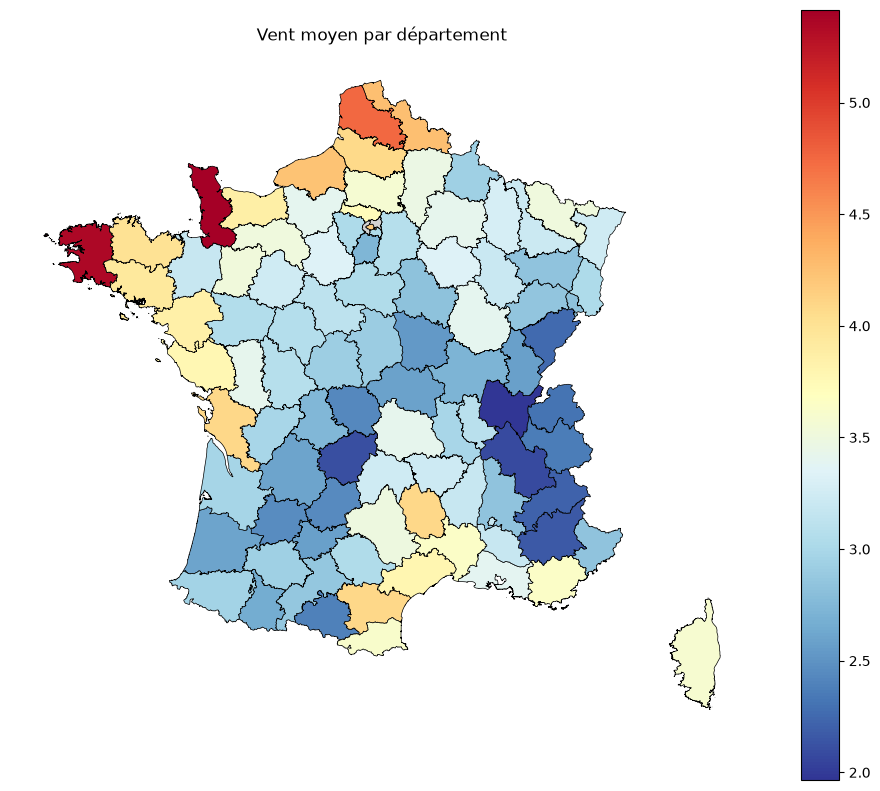

In [8]:
donnee_vent_moyen_ms = meteoDF.groupby('dep')['vent_moyen_ms'].mean().reset_index()

cartographier(donnee_vent_moyen_ms, 'vent_moyen_ms', "Vent moyen par département")

### Description de la carte : vitesse moyenne du vent par département

La carte représente, pour chaque département de France métropolitaine, la vitesse moyenne du vent (en m/s) sur l'ensemble de la période étudiée. Les valeurs vont d'environ 2,3 m/s (bleu foncé) à plus de 5,3 m/s (rouge foncé).

**Départements où le vent moyen est le plus élevé**
- Le **Finistère (29)** et la **Manche (50)** sont les deux départements où le vent est le plus fort en moyenne, avec des moyennes supérieures à 5 m/s.
- Le **Pas-de-Calais (62)** et le **Nord (59)** ressortent aussi, avec des valeurs comprises entre 4,5 et 5 m/s environ.
- Plusieurs départements de l'ouest affichent des valeurs élevées, autour de 3,5 à 4 m/s : les **Côtes-d'Armor (22)**, le **Morbihan (56)**, la **Loire-Atlantique (44)**, la **Vendée (85)** et la **Charente-Maritime (17)**.
- Dans le sud, l'**Aude (11)** et la **Lozère (48)** se détachent également, avec des valeurs proches de 4 m/s.

**Départements où le vent moyen est le plus faible**
- Les valeurs les plus basses (entre 2,3 et 2,6 m/s environ) se concentrent dans le sud-est : l'**Isère (38)**, la **Drôme (26)**, les **Hautes-Alpes (05)** et les **Alpes-de-Haute-Provence (04)**.
- Quelques départements du centre-sud (comme la **Corrèze (19)**) et du sud-ouest (comme les **Hautes-Pyrénées (65)**) présentent aussi des valeurs faibles.

**Départements aux valeurs intermédiaires**
- La grande majorité des départements du centre et de l'est de la France se situent entre 2,8 et 3,5 m/s.
- La **Corse (20)** se situe autour de 3,5 m/s.

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   INSEE_DEP            95 non-null     str     
 1   PAYS                 95 non-null     str     
 2   LIBELLE_DEPARTEMENT  95 non-null     str     
 3   SOURCE               95 non-null     str     
 4   geometry             95 non-null     geometry
 5   dep                  95 non-null     str     
 6   rafale_max_ms        93 non-null     float64 
dtypes: float64(1), geometry(1), str(5)
memory usage: 10.1 KB
None


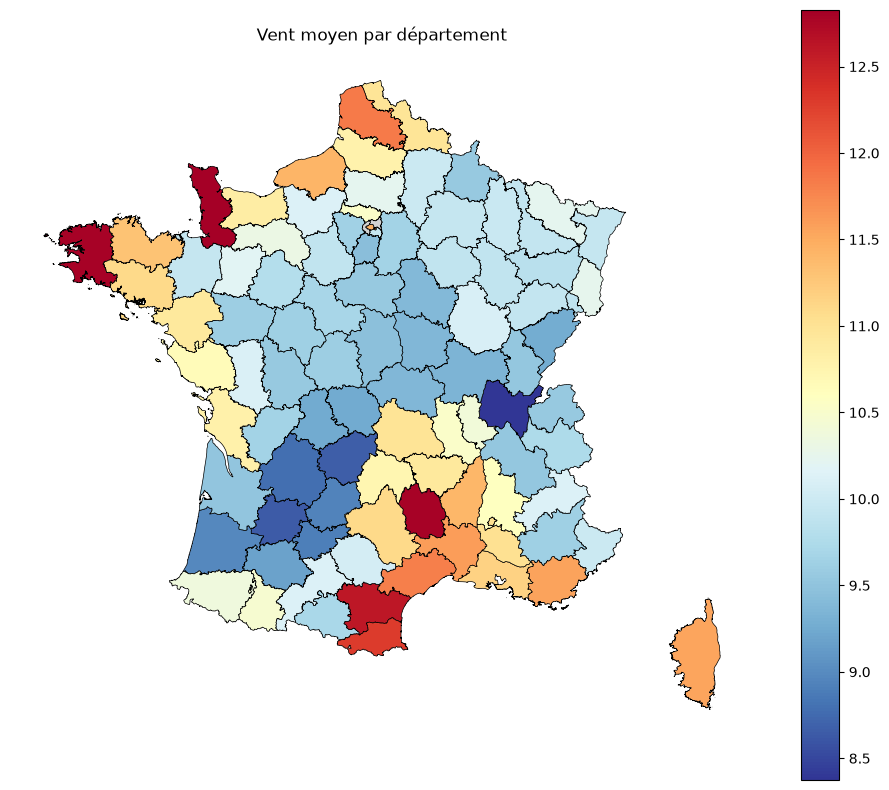

In [9]:
donnee_rafale_max_ms = meteoDF.groupby('dep')['rafale_max_ms'].mean().reset_index()
cartographier(donnee_rafale_max_ms, 'rafale_max_ms', "Vent moyen par département")

### Description de la carte : rafale maximale moyenne par département

La carte représente, pour chaque département de France métropolitaine, la rafale maximale moyenne (en m/s) sur l'ensemble de la période étudiée. Les valeurs vont d'environ 8,8 m/s (bleu foncé) à plus de 12,8 m/s (rouge foncé).

**Départements où les rafales sont les plus fortes**
- Le **Finistère (29)** et la **Manche (50)** présentent les rafales les plus élevées, au-dessus de 12,5 m/s, comme pour le vent moyen.
- La **Lozère (48)** ressort également en rouge foncé.
- L'**Aude (11)** et l'**Hérault (34)** affichent aussi des valeurs très élevées (autour de 12,3 à 12,5 m/s), suivis du **Pas-de-Calais (62)** (environ 12 m/s).
- Les départements du pourtour méditerranéen comme le **Gard (30)**, le **Var (83)** et la **Corse (20)** se situent entre 11,5 et 12 m/s.
- Plusieurs départements de l'ouest sont dans une tranche intermédiaire haute (11 à 11,7 m/s) : les **Côtes-d'Armor (22)**, le **Morbihan (56)**, l'**Ile-et-Vilaine (35)**, la **Loire-Atlantique (44)** et la **Vendée (85)**.

**Départements où les rafales sont les plus faibles**
- Le minimum (environ 8,8 m/s) se situe dans l'**Ain (01)**, qui apparaît en bleu foncé.
- Un ensemble de départements du centre-sud-ouest affiche des valeurs basses (9 à 9,3 m/s) : la **Dordogne (24)**, le **Lot (46)**, la **Corrèze (19)** et le **Lot-et-Garonne (47)** notamment.

**Départements aux valeurs intermédiaires**
- La majorité des départements du centre, du nord-est et de l'est se situent entre 9,5 et 10,3 m/s.

**Comparaison avec la carte du vent moyen**
- Les deux cartes se ressemblent : le **Finistère** et la **Manche** ont les valeurs les plus hautes dans les deux cas, et le centre de la France reste plutôt bas.
- Quelques différences : la **Lozère**, l'**Aude** et l'**Hérault** ressortent bien plus nettement pour les rafales que pour le vent moyen, et la **Corse** passe d'une valeur intermédiaire à une valeur élevée.
- Inversement, le **Nord (59)** ressort moins pour les rafales que pour le vent moyen.

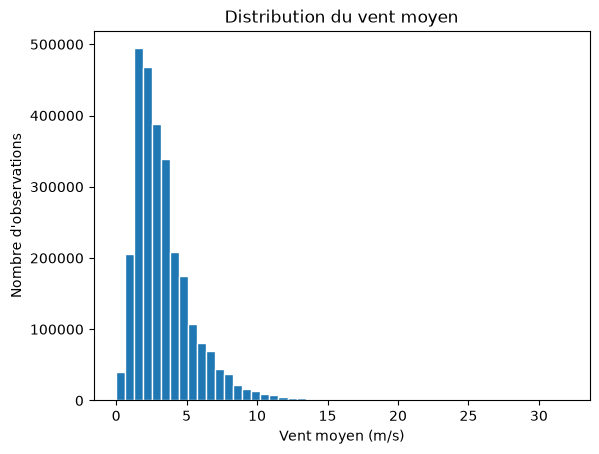

In [10]:
histogramme(meteoDF["vent_moyen_ms"], "Distribution du vent moyen", "Vent moyen (m/s)", 50)

### Distribution du vent moyen

Le pic se situe entre 1,5 et 2 m/s (environ 490 000 observations), et la grande majorité des valeurs sont comprises entre 1 et 5 m/s. Les effectifs décroissent ensuite rapidement : au-delà de 10 m/s, les barres sont à peine visibles.

L'axe s'étend jusqu'à environ 30 m/s, car quelques observations isolées atteignent ces valeurs, mais elles sont trop peu nombreuses pour apparaître sur le graphique.

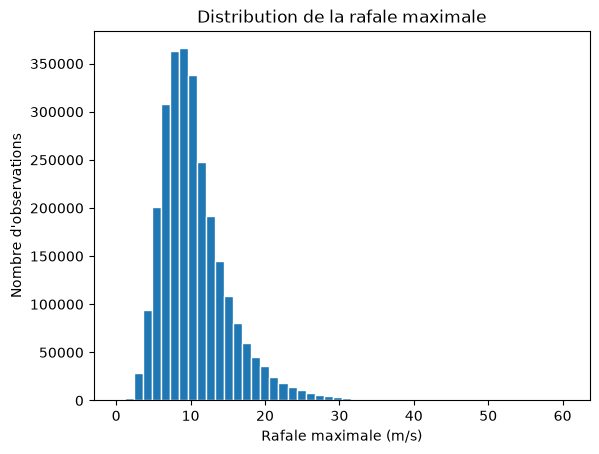

In [11]:
histogramme(meteoDF["rafale_max_ms"], "Distribution de la rafale maximale", "Rafale maximale (m/s)", 50)

### Distribution de la rafale maximale

Le pic se situe entre 8 et 10 m/s (environ 365 000 observations), et la grande majorité des valeurs sont comprises entre 5 et 15 m/s. Les effectifs diminuent ensuite progressivement : les barres deviennent très faibles au-delà de 25 m/s et disparaissent visuellement vers 30 m/s.

### **Données traumatismes**

### Import des données

Nous avons deux sources de données : \
Les données du taux de passage aux urgences pour traumatisme, entre 2021 et 2026 disponibles sur Odissé : https://odisse.santepubliquefrance.fr/explore/assets/traumatisme-passages-aux-urgences-et-actes-sos-medecins-departement/ \
Les données du nombre d'hospitalisation par départment de l'enquête de la DREES : « Passages aux urgences entre 2017 et 2023 : des dynamiques contrastées selon les départements »

Nous avons téléverser ces données au format parquet dans ce bucket public pour pouvoir les exploiter facilement, l'API limitant le nombre de requêtes. \
Url du bucket : https://datalab.sspcloud.fr/s3/jvalade/projet_2A_S1/?profile=anonymous

1. Import des fichiers parquet depuis le bucket.
2. On récupère les numéros de semaine au format iso, pour pouvoir y faire le merge. En effet dans les données de la DREES on a un relevé journalier, contrairement au fichier d'Odissé pour lequel on a un relevé hebdomadaire.
3. On somme par semaine le nombre d'hospitalisations.
4. On joint les données sur les départements et le numéro de semaine.
5. Puis on peut ajouter une colonne du nombre d'hospitalisations pour traumatisme par semaine par département.

In [12]:
import pandas as pd

bobos = pd.read_parquet("https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/traumatisme-passages-aux-urgences-et-actes-sos-medecins-departement.parquet")
nb_hospi = pd.read_parquet("https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/series_longues_passages_urgences_2017_2023.parquet")

nb_hospi["date"] = pd.to_datetime(nb_hospi["date"])
nb_hospi["semaine"] = nb_hospi["date"].dt.isocalendar().week

bobos = bobos[bobos['dep'] != '90'] #Les données du Territoire de Belfort n'ont pas été 
bobos["date_complet"] = pd.to_datetime(bobos["date_complet"])
bobos["semaine"] = bobos["date_complet"].dt.isocalendar().week

nb_hospi["cle_semaine"] = list(zip(nb_hospi["dep"], nb_hospi["semaine"], nb_hospi["date"].dt.isocalendar().year)) #on utilise zip pour concaténer les colonnes selon l'axis 1
bobos["cle_semaine"] = list(zip(bobos["dep"], bobos["semaine"], bobos["date_complet"].dt.isocalendar().year))

nb_hospi_semaine = nb_hospi.groupby("cle_semaine")[["nb_passages"]].sum()

nb_bobos = bobos.merge(nb_hospi_semaine, on="cle_semaine", how= 'inner')

nb_bobos = nb_bobos[nb_bobos["sursaud_cl_age_gene"] == "Tous âges"]

nb_bobos["nb_traumas"] = nb_bobos["taux_passages_trauma_sau"] * nb_bobos["nb_passages"] / 100_000 #le taux de passage correspond au nombre pour 100 000 passages
nb_bobos = nb_bobos[["cle_semaine", "date_complet", "dep", "nb_traumas"]] #on ne garde que les variables d'intérêt

nb_bobos.head()


,cle_semaine,date_complet,dep,nb_traumas
1,"(75, 52, 2023)",2023-12-25,75,2001.502367
4,"(89, 52, 2023)",2023-12-25,89,501.896406
7,"(69, 52, 2023)",2023-12-25,69,2145.691326
14,"(14, 52, 2023)",2023-12-25,14,992.732680
16,"(15, 52, 2023)",2023-12-25,15,210.902970


### Visualisation des données par département


In [13]:
url_pop = "https://minio.lab.sspcloud.fr/jvalade/projet_2A_S1/donnees_departements.csv"

pop = pd.read_csv(url_pop, sep=";")
pop = pop[["DEP", "PTOT"]]
nb_bobos = nb_bobos.merge(pop, left_on ='dep', right_on = 'DEP', how='inner')
nb_bobos['trauma_par_pop'] = nb_bobos["nb_traumas"] / nb_bobos["PTOT"]
nb_bobos = nb_bobos[["cle_semaine", "date_complet", "dep", "nb_traumas", "PTOT", "trauma_par_pop"]]
nb_bobos.head()

,cle_semaine,date_complet,dep,nb_traumas,PTOT,trauma_par_pop
0,"(75, 52, 2023)",2023-12-25,75,2001.502367,2119412,0.000944
1,"(89, 52, 2023)",2023-12-25,89,501.896406,340359,0.001475
2,"(69, 52, 2023)",2023-12-25,69,2145.691326,1940015,0.001106
3,"(14, 52, 2023)",2023-12-25,14,992.732680,722979,0.001373
4,"(15, 52, 2023)",2023-12-25,15,210.902970,148813,0.001417


nb_bobos_moy = nb_bobos.groupby('dep')['trauma_par_pop'].mean().reset_index()
cartographier(nb_bobos_moy, 'trauma_par_pop', "Traumatismes par semaine par personne par département")

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 95 entries, 0 to 94
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   INSEE_DEP            95 non-null     str     
 1   PAYS                 95 non-null     str     
 2   LIBELLE_DEPARTEMENT  95 non-null     str     
 3   SOURCE               95 non-null     str     
 4   geometry             95 non-null     geometry
 5   dep                  92 non-null     str     
 6   trauma_par_pop       92 non-null     float64 
dtypes: float64(1), geometry(1), str(5)
memory usage: 10.1 KB
None


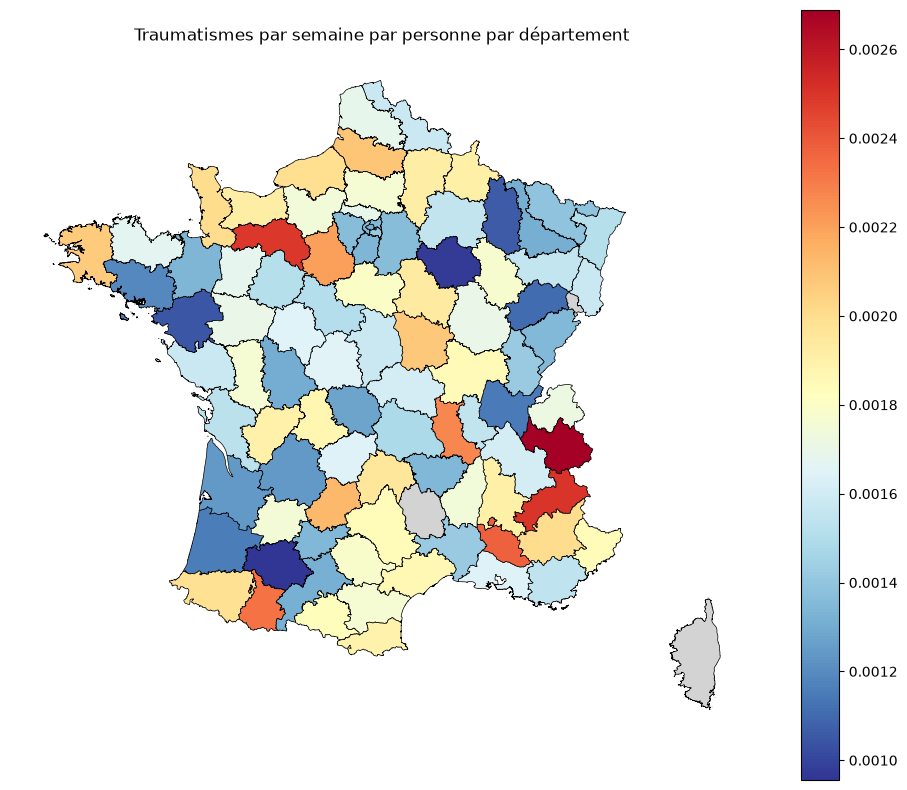

In [14]:
nb_bobos_moy = nb_bobos.groupby('dep')['trauma_par_pop'].mean().reset_index()
cartographier(nb_bobos_moy, 'trauma_par_pop', "Traumatismes par semaine par personne par département")

On ne constate pas de nette corrélation entre les cartes de traumatismes et celles des vents, mais on reconnaît les hauts taux élevés de la Normandie, du Finistère et du bassin méditerranéen. \
Cependant on a des résultats opposés dans les Alpes, les taux de traumatismes sont très élevés, ce qui peut peut-être être lié aux sports d'hiver.

### **Données crime**

### Import des données

On a d'abord voulu utiliser les données de Légifrance, mais l'obtention des clés API est très conditionnée.

On essaie d'utiliser des données disponibles sur Wikipédia : \
source : https://fr.wikipedia.org/wiki/Liste_d'affaires_criminelles_fran%C3%A7aises_depuis_1900 \
- **Faits divers** recensés sur Wikipedia
- Nature des données : tableaux triés par décénies
- Plage de données : **1900 à 2020**
- Colonnes d'intérêt : Départements et résumés avec **des dates** \
*Limite : ce sont des faits divers très médiatisés, mais on peut supposer qu'il n'y a pas de biais de sélection par rapport à la météo.* 


In [15]:
DEPARTMENTS = {
    '01': 'Ain', '02': 'Aisne', '03': 'Allier', '04': 'Alpes-de-Haute-Provence', '05': 'Hautes-Alpes','06': 'Alpes-Maritimes', '07': 'Ardèche', '08': 'Ardennes', '09': 'Ariège', '10': 'Aube', '11': 'Aude','12': 'Aveyron', '13': 'Bouches-du-Rhône','14': 'Calvados', '15': 'Cantal', '16': 'Charente','17': 'Charente-Maritime', '18': 'Cher', '19': 'Corrèze', '2A': 'Corse-du-Sud', '2B': 'Haute-Corse','21': 'Côte-d\'Or', '22': 'Côtes-d\'Armor', '23': 'Creuse', '24': 'Dordogne', '25': 'Doubs', '26': 'Drôme','27': 'Eure', '28': 'Eure-et-Loir', '29': 'Finistère', '30': 'Gard', '31': 'Haute-Garonne', '32': 'Gers','33': 'Gironde', '34': 'Hérault', '35': 'Ille-et-Vilaine', '36': 'Indre', '37': 'Indre-et-Loire','38': 'Isère', '39': 'Jura', '40': 'Landes', '41': 'Loir-et-Cher', '42': 'Loire', '43': 'Haute-Loire','44': 'Loire-Atlantique', '45': 'Loiret', '46': 'Lot', '47': 'Lot-et-Garonne', '48': 'Lozère','49': 'Maine-et-Loire', '50': 'Manche', '51': 'Marne', '52': 'Haute-Marne', '53': 'Mayenne','54': 'Meurthe-et-Moselle', '55': 'Meuse', '56': 'Morbihan', '57': 'Moselle', '58': 'Nièvre', '59': 'Nord','60': 'Oise', '61': 'Orne', '62': 'Pas-de-Calais', '63': 'Puy-de-Dôme', '64': 'Pyrénées-Atlantiques','65': 'Hautes-Pyrénées', '66': 'Pyrénées-Orientales', '67': 'Bas-Rhin', '68': 'Haut-Rhin', '69': 'Rhône','70': 'Haute-Saône', '71': 'Saône-et-Loire', '72': 'Sarthe', '73': 'Savoie', '74': 'Haute-Savoie','75': 'Paris', '76': 'Seine-Maritime', '77': 'Seine-et-Marne', '78': 'Yvelines', '79': 'Deux-Sèvres','80': 'Somme', '81': 'Tarn', '82': 'Tarn-et-Garonne', '83': 'Var', '84': 'Vaucluse', '85': 'Vendée','86': 'Vienne', '87': 'Haute-Vienne', '88': 'Vosges', '89': 'Yonne', '90': 'Territoire de Belfort','91': 'Essonne', '92': 'Hauts-de-Seine', '93': 'Seine-Saint-Denis', '94': 'Val-de-Marne', '95': 'Val-d\'Oise','971': 'Guadeloupe', '972': 'Martinique', '973': 'Guyane', '974': 'La Réunion', '976': 'Mayotte',
}

In [ ]:
url = "https://fr.wikipedia.org/wiki/Liste_d'affaires_criminelles_fran%C3%A7aises_depuis_1900"

req = requests.get(url, headers={"User-Agent":"School Data Science Project"})

request_text = req.content
page = bs4.BeautifulSoup(request_text, "lxml")

faitsDivDF = extraction_wikipedia(page) #fonction dans le fichier tierce

MOIS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet",
        "août", "septembre", "octobre", "novembre", "décembre"]
MOTIF = re.compile(r"(\d{1,2})(?:er)? (" + "|".join(MOIS) + r") (\d{4})")


def extraire_date(texte):
    """
    Renvoie la première date rencontrée au format JJ-MM-AAAA, Nan si pas de date dans le texte
    """
    m = MOTIF.search(str(texte))
    if not m:
        return None
    jour, mois, annee = m.groups()
    return f"{int(jour):02d}-{MOIS.index(mois) + 1:02d}-{annee}"

faitsDivDF = faitsDivDF[["Département(S) [ Note 2 ]", "Résumé"]]
faitsDivDF.columns = ["Département" , "Résumé"]

for i in range(len(faitsDivDF)) : 
    faitsDivDF.loc[i, "date"] = extraire_date(faitsDivDF.loc[i, "Résumé"])

departement_df = pd.DataFrame.from_dict(DEPARTMENTS, orient = 'index', columns=["Département"])
departement_df = departement_df.reset_index()
departement_df.columns = ["Numéro", "Département"]

faitsDivDF = faitsDivDF.merge(departement_df, on="Département", how = "inner")

faitsDivDF = faitsDivDF.dropna()
faitsDivDF["date"] = pd.to_datetime(faitsDivDF["date"], format= f'%d-%m-%Y')
faitsDivDF.columns = ["Département", "Résumé", "DATE", "dep"]
faitsDivDF.head()

<class 'pandas.DataFrame'>
Index: 310 entries, 1 to 380
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Département  310 non-null    str           
 1   Résumé       310 non-null    str           
 2   DATE         310 non-null    datetime64[us]
 3   dep          310 non-null    str           
dtypes: datetime64[us](1), str(3)
memory usage: 60.8 KB


## Jointure des données

On peut à présent joindre les données du vent, des traumatismes et des crimes.

1. On crée le DataFrame `ventBobos`sur la clé commune des semaines, département.
2. On crée le DataFrame `ventCrime` pour les entrées que l'on possède.
3. On effectue des premières observations de corrélation brute.

In [25]:
ventBobos = meteo_sem.merge(nb_bobos, on = "cle_semaine", how = "inner")

ventBobos.head()

,cle_semaine,vent_moyen_ms,rafale_max_ms,date_complet,dep,nb_traumas,PTOT,trauma_par_pop
0,"(01, 1, 2021)",1.434146,6.012500,2021-01-04,01,644.245698,694945,0.000927
1,"(01, 1, 2022)",2.392857,10.825000,2022-01-03,01,643.539521,694945,0.000926
2,"(01, 1, 2023)",1.661905,7.240816,2023-01-02,01,626.187867,694945,0.000901
3,"(01, 2, 2021)",1.587500,6.495652,2021-01-11,01,635.084512,694945,0.000914
4,"(01, 2, 2022)",1.614634,6.291667,2022-01-10,01,654.919870,694945,0.000942


In [27]:
ventCrime = meteo_jour.merge(faitsDivDF, on = ["DATE", "dep"], how = "inner")

ventCrime.head()

,DATE,dep,vent_moyen_ms,rafale_max_ms,Département,Résumé
0,2016-01-05,01,2.200000,8.883333,Ain,"Le 5 janvier 2016 à Ambérieu-en-Bugey, Anne-Ch..."
1,2016-03-13,71,4.057143,12.757143,Saône-et-Loire,"Le 13 mars 2016 à la Clayette, Valérie Bacot, ..."
2,2016-06-13,78,3.116667,8.250000,Yvelines,"Le 13 juin 2016 à Magnanville, assassinat d'un..."
3,2016-07-14,06,3.815000,18.342105,Alpes-Maritimes,"Le 14 juillet 2016 à Nice, Mohamed Lahouaiej-B..."
4,2016-07-26,76,2.585714,7.971429,Seine-Maritime,"Le 26 juillet 2016 à Saint-Étienne-du-Rouvray,..."


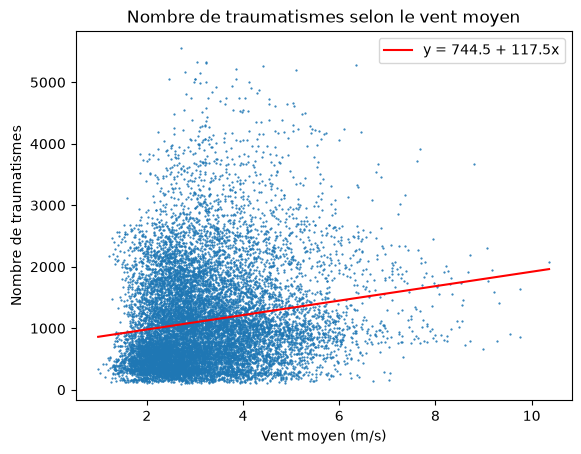

r = 0.164  (r² = 0.027)
p-value = 2.88e-84


In [19]:
x = ventBobos["vent_moyen_ms"]
y = ventBobos["nb_traumas"]
regression(x, y, "Nombre de traumatismes selon le vent moyen", "Vent moyen (m/s)", "Nombre de traumatismes")

### Interprétation : nombre de traumatismes selon le vent moyen

Le nuage de points et la droite de régression (y = 735,3 + 118,4x) montrent une relation **positive mais faible** entre le vent moyen et le nombre de traumatismes. En moyenne, une augmentation de 1 m/s du vent moyen s'accompagne d'environ 118 traumatismes supplémentaires.

Le coefficient de corrélation est de **r = 0,165**, soit un **r² = 0,027** : le vent moyen n'explique qu'environ 2,7 % de la variabilité du nombre de traumatismes. À vent égal, autour de 3 m/s, le nombre de traumatismes va de quelques centaines à plus de 5 000.

La **p-value (ordre de grandeur : 10⁻⁸⁶)** est quasi nulle : la pente est significativement différente de zéro, donc la relation n'est pas due au hasard. La relation est donc **réelle mais faible**.

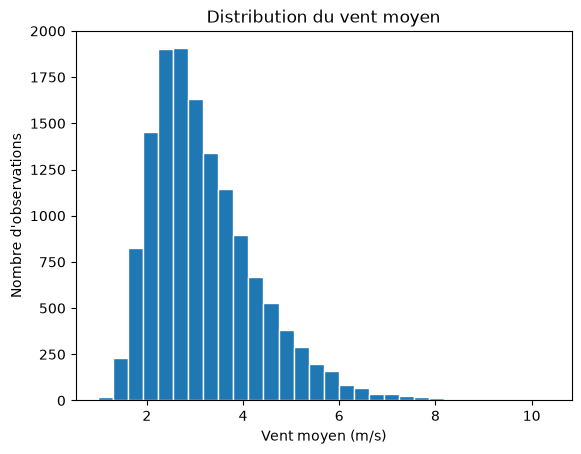

In [20]:
x = ventBobos["vent_moyen_ms"]
histogramme(x, "Distribution du vent moyen", "Vent moyen (m/s)")

### Distribution du vent moyen

Le vent moyen est faible à modéré (mode autour de 3 m/s) et sa distribution est asymétrique à droite : les vitesses supérieures à 6 m/s sont rares.

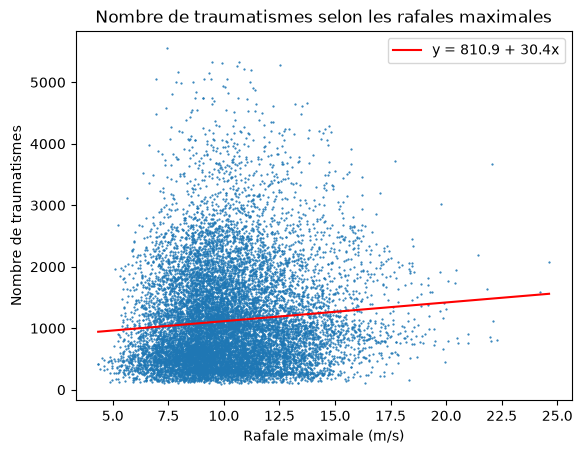

r = 0.090  (r² = 0.008)
p-value = 2.86e-26


In [21]:
x = ventBobos["rafale_max_ms"]
y = ventBobos["nb_traumas"]
regression (x, y, "Nombre de traumatismes selon les rafales maximales", "Rafale maximale (m/s)", "Nombre de traumatismes")


### Interprétation : nombre de traumatismes selon les rafales maximales

Le nuage de points et la droite de régression (y = 805,0 + 30,4x) montrent une relation **positive mais très faible** entre la rafale maximale et le nombre de traumatismes. En moyenne, une augmentation de 1 m/s de la rafale maximale s'accompagne d'environ 30 traumatismes supplémentaires.

Le coefficient de corrélation est de **r = 0,090**, soit un **r² = 0,008** : la rafale maximale n'explique qu'environ 0,8 % de la variabilité du nombre de traumatismes. À rafale égale, les valeurs sont très dispersées : autour de 10 m/s, le nombre de traumatismes va de quelques centaines à plus de 5 000.

La **p-value (ordre de grandeur : 10⁻²⁶)** est quasi nulle : la pente est significativement différente de zéro, donc la relation n'est pas due au hasard. La relation est donc **réelle mais très faible**, et plus faible que pour le vent moyen (r = 0,165 et r² = 0,027).

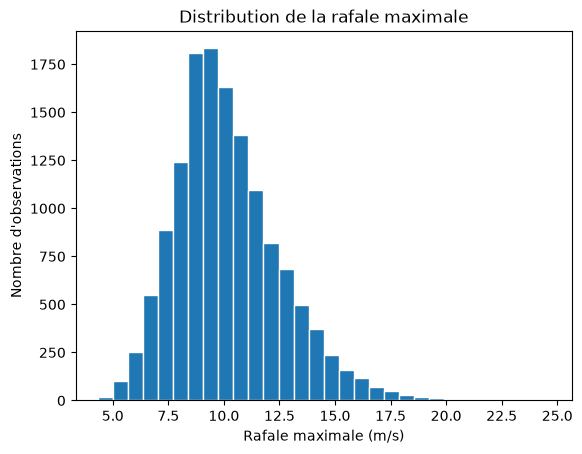

In [22]:
### Note : graphique à comparer avec les moyennes de vent

x = ventBobos["rafale_max_ms"]
histogramme(x, "Distribution de la rafale maximale", "Rafale maximale (m/s)", bins=30)

### Distribution de la rafale maximale

La rafale maximale est modérée (mode autour de 9 à 10 m/s) et sa distribution est asymétrique à droite : la majorité des valeurs se situe entre 7 et 13 m/s, et les rafales supérieures à 15 m/s sont peu fréquentes.